# 🌍 Atlas Horizon Group · Fase 2: de los datos al data warehouse

**Objetivo:** convertir un dataset público de alojamientos de Londres (Inside Airbnb, febrero 2020) en un **data warehouse en estrella** que mida los KPIs del *Proceso 4 · Gestión de la oferta de alojamiento*, diseñado en la Fase 1.

| Paso | Qué se hace | Herramienta |
|---|---|---|
| 1 | Análisis exploratorio y calidad del dato | pandas, matplotlib |
| 2 | Conexión con el proceso de negocio | modelado dimensional |
| 3 | ETL: limpieza y preparación (staging) | pandas |
| 4 | Carga del modelo en estrella | SQL · DuckDB |
| 5 | Cálculo de KPIs frente a metas | SQL |
| 6 | Exportación para el informe y el dashboard | CSV |

> **Contexto de negocio.** Atlas Horizon es un operador de expediciones de lujo. Antes de cada salida, clientes y staff pasan 1-3 noches en Londres para el *briefing* de seguridad (sede supuesta en South Kensington) y el vuelo desde Heathrow. El equipo de logística necesita saber **qué parte de la oferta de alojamiento de la ciudad es apta para sus estándares, a qué precio y a qué distancia de la sede.**

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import duckdb

pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "listings_london_2020-02.csv.gz"
PROC = ROOT / "data" / "processed"
SQL = ROOT / "sql"
PROC.mkdir(parents=True, exist_ok=True)

raw = pd.read_csv(RAW, keep_default_na=True)
print(f"Registros: {raw.shape[0]:,} · Variables: {raw.shape[1]}")
raw.head(3)

Registros: 87,531 · Variables: 16


,id,name,host_id,host_name,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,expedition_type
0,35778619,Love Actually House,182631388,런던러브액츄얼리하우스,Lambeth,51.49985,-0.11169,Private room,110,1,3,2019-12-14,0.37,5,287,Científica
1,35779007,Retreat to a stylish studio in Chelsea,19029045,Olivia,Kensington and Chelsea,51.49332,-0.17816,Entire home/apt,149,3,0,NaN,0.00,1,34,Aventura
2,35779289,Love Actually House,182631388,런던러브액츄얼리하우스,Lambeth,51.49984,-0.11192,Private room,190,1,0,NaN,0.00,5,284,Científica


## 1. Análisis exploratorio

### 1.1 Diccionario de variables (lectura de negocio)

| Variable | Significado para Atlas Horizon | Uso en el modelo |
|---|---|---|
| `id` | Identificador del alojamiento | Dimensión degenerada |
| `name` | Título del anuncio | Descriptivo (no se modela) |
| `host_id`, `host_name` | Proveedor del alojamiento | `dim_proveedor` (sin nombre, por privacidad) |
| `neighbourhood` | Barrio (borough) de Londres | `dim_barrio` |
| `latitude`, `longitude` | Ubicación | Distancia a la sede |
| `room_type` | Tipo de alojamiento | `dim_segmento` |
| `price` | Precio por noche (£) | Medida |
| `minimum_nights` | Estancia mínima | Medida y criterio de homologación |
| `number_of_reviews`, `reviews_per_month`, `last_review` | Reputación y actividad | Medidas y criterios |
| `calculated_host_listings_count` | Nº de anuncios del proveedor | Tipo de proveedor |
| `availability_365` | Días disponibles en el próximo año | Medida |
| `expedition_type` | Columna heredada de la versión anterior | **Se descarta** y se rediseña (ver 1.3) |

In [2]:
perfil = pd.DataFrame({
    "tipo": raw.dtypes.astype(str),
    "nulos": raw.isna().sum(),
    "% nulos": (raw.isna().mean() * 100).round(2),
    "valores únicos": raw.nunique(),
})
perfil

,tipo,nulos,% nulos,valores únicos
id,int64,0,0.00,87531
name,str,1,0.00,84908
host_id,int64,0,0.00,54488
host_name,str,0,0.00,14878
neighbourhood,str,0,0.00,33
latitude,float64,0,0.00,20792
longitude,float64,0,0.00,32389
room_type,str,0,0.00,4
price,int64,0,0.00,999
minimum_nights,int64,0,0.00,115


In [3]:
print(f"Duplicados por id: {raw['id'].duplicated().sum()}")
print(f"Precio = 0: {(raw['price'] == 0).sum()}")
print(f"Precio > 1.000 £/noche: {(raw['price'] > 1000).sum()}")
print(f"Estancia mínima > 30 noches: {(raw['minimum_nights'] > 30).sum()}")
print(f"Sin disponibilidad (0 días): {(raw['availability_365'] == 0).mean():.1%}")
print(f"Tipos sin mapear en la versión anterior (expedition_type nulo): {raw['expedition_type'].isna().sum()}")
raw[["price", "minimum_nights", "number_of_reviews", "reviews_per_month",
     "calculated_host_listings_count", "availability_365"]].describe(percentiles=[.5, .9, .99]).round(1)

Duplicados por id: 0
Precio = 0: 22
Precio > 1.000 £/noche: 336
Estancia mínima > 30 noches: 1010
Sin disponibilidad (0 días): 34.0%
Tipos sin mapear en la versión anterior (expedition_type nulo): 821


,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,87531.0,87531.0,87531.0,87531.0,87531.0,87531.0
mean,128.0,4.2,17.9,0.8,20.1,119.5
std,228.3,18.7,37.9,1.2,94.9,133.9
min,0.0,1.0,0.0,0.0,1.0,0.0
50%,83.0,2.0,4.0,0.4,1.0,64.0
90%,236.0,6.0,48.0,2.3,29.0,351.0
99%,900.0,58.0,191.0,5.8,898.0,365.0
max,10000.0,1125.0,756.0,23.0,898.0,365.0


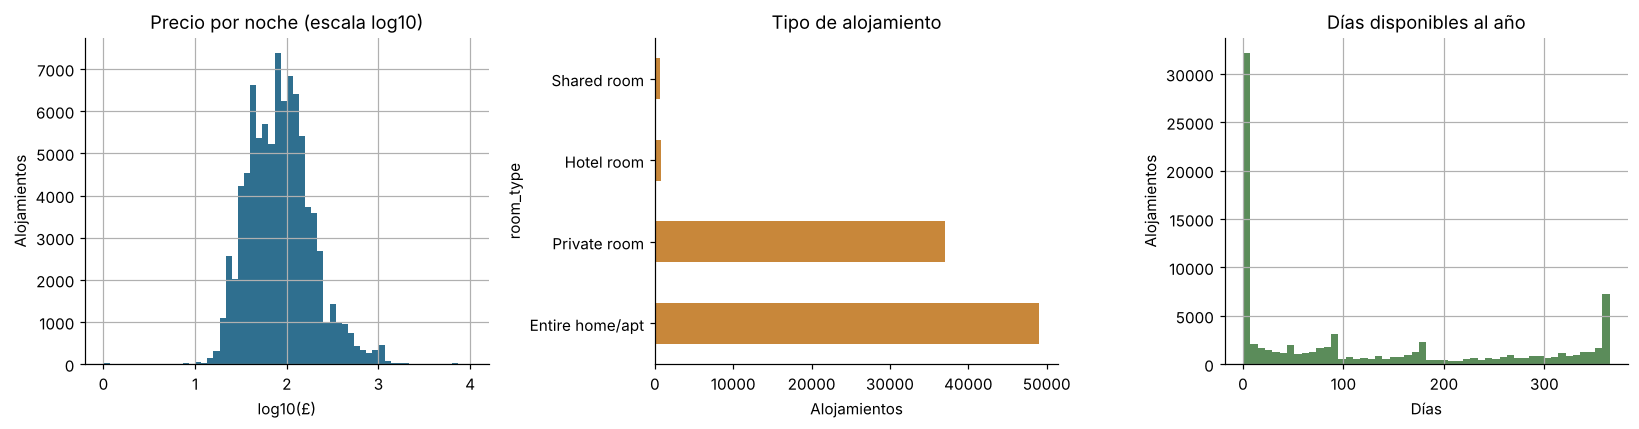

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
raw["price"].clip(lower=1).pipe(np.log10).hist(bins=60, ax=ax[0], color="#2f6f8f")
ax[0].set(title="Precio por noche (escala log10)", xlabel="log10(£)", ylabel="Alojamientos")
raw["room_type"].value_counts().plot.barh(ax=ax[1], color="#c8873a")
ax[1].set(title="Tipo de alojamiento", xlabel="Alojamientos")
raw["availability_365"].hist(bins=50, ax=ax[2], color="#5b8c5a")
ax[2].set(title="Días disponibles al año", xlabel="Días", ylabel="Alojamientos")
plt.tight_layout(); plt.show()

### 1.2 Respuestas al análisis exploratorio

- **¿Cuántos registros?** 87.531 alojamientos y 16 variables. El fichero original tenía 87.571; las 40 filas sin nombre de anuncio o de anfitrión ya se eliminaron en la versión anterior.
- **¿Tipos correctos?** Casi todos. `last_review` debe ser fecha e `id`/`host_id` son identificadores, no cantidades.
- **¿Nulos?** `last_review` está vacío en ~23,6 % de los casos: son alojamientos **sin ninguna reseña**, así que no se imputan; se interpretan como "sin actividad demostrada". Hay 1 anuncio sin título.
- **¿Anómalos?**
  - 22 alojamientos con **precio 0** (error de carga).
  - Precios extremos (hasta 10.000 £/noche, e incluso habitaciones compartidas a 7.000 £): se marcan como atípicos los que superan el **percentil 99 de su tipo**. No se borran; se excluyen de las medias.
  - Estancias mínimas de hasta 1.125 noches: son alquileres de larga duración, no aptos para estancias de 1-3 noches.
- **¿Hay que recodificar?** Sí. En la versión anterior, `Hotel room` (821 alojamientos) **no estaba mapeado** y el tipo de alojamiento se convertía en tipo de expedición sin justificación de negocio. Se rediseña como **segmento de huésped** (1.3).
- **¿Faltan datos?** Para el objetivo (cartera de alojamientos para estancias previas a expedición) basta. Se calcula la **distancia a la sede** a partir de latitud y longitud. Una evolución natural sería integrar capturas mensuales para analizar estacionalidad.

### 1.3 Conexión con el proceso de negocio

Estos datos no vienen de una expedición, sino del **proceso de aprovisionamiento** que la precede. Por eso se añade a la Fase 1 un **Proceso 4: Gestión de la oferta de alojamiento en hubs de partida**. Así, las dos fases quedan conectadas: la Fase 1 lo diseña y esta fase lo implementa.

| Elemento | Definición |
|---|---|
| **Hecho** | La oferta de un alojamiento en una fecha de captura |
| **Tipo de tabla de hechos** | Snapshot periódico (foto mensual de la oferta) |
| **Granularidad** | 1 fila = 1 alojamiento × 1 fecha de captura |
| **Dimensiones** | `dim_tiempo`, `dim_barrio` (nivel de la dimensión conformada DIM_GEO), `dim_segmento`, `dim_proveedor` |
| **Medidas** | precio/noche (no aditiva), días disponibles (semi-aditiva), nº reseñas (aditiva), distancia a la sede (no aditiva), flags de homologación, actividad y precio atípico (aditivas como contadores) |
| **Tasa de refresco** | Mensual |

**Recodificación justificada del tipo de alojamiento → segmento de huésped:**

| `room_type` | Segmento Atlas | Quién lo usa |
|---|---|---|
| Entire home/apt | Base privada | Clientes UHNW y grupos (privacidad y espacio para el briefing) |
| Hotel room | Hotel | Clientes que requieren servicios de hotel |
| Private room | Habitación individual | Staff técnico, científicos y guías |
| Shared room | Compartido | Staff de apoyo (uso excepcional) |

**Criterios de homologación** (un alojamiento es *apto* para Atlas si cumple todos):
precio válido (> 0 y ≤ p99 de su tipo) · estancia mínima ≤ 7 noches · ≥ 30 días disponibles · ≥ 5 reseñas · al menos una reseña en los últimos 12 meses.

## 2. ETL: limpieza y preparación del *staging*

In [5]:
stg = raw.copy()

# 1) Selección: se descarta la recodificación heredada (se rediseña en SQL)
stg = stg.drop(columns=["expedition_type"])

# 2) Tipos
stg["last_review"] = pd.to_datetime(stg["last_review"], errors="coerce")
stg["id"] = stg["id"].astype("int64")
stg["host_id"] = stg["host_id"].astype("int64")

# 3) Nulos
stg["name"] = stg["name"].fillna("Sin título")
stg["reviews_per_month"] = stg["reviews_per_month"].fillna(0)   # sin reseñas = 0 reseñas/mes
# last_review se mantiene nulo a propósito: significa "nunca reseñado"

# 4) Duplicados
antes = len(stg)
stg = stg.drop_duplicates(subset="id")
print(f"Duplicados eliminados: {antes - len(stg)}")

# 5) Normalización de texto
for col in ["neighbourhood", "room_type", "host_name"]:
    stg[col] = stg[col].str.strip()

# 6) Coherencia de rangos
assert stg["availability_365"].between(0, 365).all()
assert (stg["price"] >= 0).all()
assert stg[["latitude", "longitude"]].notna().all().all()

# Los precios 0 y extremos NO se borran: se marcan en la tabla de hechos (flag_precio_atipico)
print(f"Staging listo: {stg.shape[0]:,} filas · {stg.shape[1]} columnas")
stg.dtypes

Duplicados eliminados: 0
Staging listo: 87,531 filas · 15 columnas


id                                         int64
name                                         str
host_id                                    int64
host_name                                    str
neighbourhood                                str
latitude                                 float64
longitude                                float64
room_type                                    str
price                                      int64
minimum_nights                             int64
number_of_reviews                          int64
last_review                       datetime64[us]
reviews_per_month                        float64
calculated_host_listings_count             int64
availability_365                           int64
dtype: object

## 3. Carga del data warehouse (DuckDB)

El modelo se define en [`sql/01_modelo_estrella.sql`](../sql/01_modelo_estrella.sql). Las reglas de negocio (homologación, precios atípicos, distancia a la sede) viven en SQL, de modo que cualquier herramienta de BI que lea el almacén obtiene las mismas cifras: **una única versión de la verdad**.

In [6]:
con = duckdb.connect(str(ROOT / "data" / "atlas_horizon.duckdb"))
con.register("stg_df", stg)
con.sql("CREATE OR REPLACE TABLE stg_listings AS SELECT * FROM stg_df")
con.sql((SQL / "01_modelo_estrella.sql").read_text(encoding="utf-8"))
con.sql((SQL / "02_kpis.sql").read_text(encoding="utf-8"))

con.sql("""
    SELECT 'fact_oferta_alojamiento' AS tabla, COUNT(*) AS filas FROM fact_oferta_alojamiento
    UNION ALL SELECT 'dim_barrio', COUNT(*) FROM dim_barrio
    UNION ALL SELECT 'dim_segmento', COUNT(*) FROM dim_segmento
    UNION ALL SELECT 'dim_proveedor', COUNT(*) FROM dim_proveedor
    UNION ALL SELECT 'dim_tiempo', COUNT(*) FROM dim_tiempo
""").df()

,tabla,filas
0,fact_oferta_alojamiento,87531
1,dim_barrio,33
2,dim_segmento,4
3,dim_proveedor,54488
4,dim_tiempo,1


In [7]:
# Control de calidad: la carga no pierde filas y cada hecho tiene sus dimensiones
assert con.sql("SELECT COUNT(*) FROM fact_oferta_alojamiento").fetchall()[0][0] == len(stg)
assert con.sql("""SELECT COUNT(*) FROM fact_oferta_alojamiento
                  WHERE id_barrio IS NULL OR id_segmento IS NULL OR id_proveedor IS NULL""").fetchall()[0][0] == 0
con.sql("SELECT * FROM dim_segmento").df()

,id_segmento,tipo_alojamiento,segmento_atlas,perfil_huesped
0,1,Entire home/apt,Base privada,Clientes UHNW y grupos (privacidad y espacio p...
1,2,Hotel room,Hotel,Clientes que requieren servicios de hotel
2,3,Private room,Habitación individual,"Staff técnico, científicos y guías"
3,4,Shared room,Compartido,Staff de apoyo (uso excepcional)


## 4. KPIs del Proceso 4 frente a sus metas

Calculados en [`sql/02_kpis.sql`](../sql/02_kpis.sql). Las metas son supuestos de negocio definidos en el diseño (`docs/diseno_bi.md`).

In [8]:
kpis = con.sql("SELECT * FROM v_kpis").df()
kpis

,id_kpi,kpi,unidad,valor,meta,operador,estado,accion
0,PI_ALO_01,Tasa de homologación de la oferta,%,29.3,25,>=,Cumple,Ampliar criterios o buscar plataformas alterna...
1,PI_ALO_02,Precio medio por noche · bases privadas homolo...,£,158.0,150,<=,No cumple,Negociar tarifas por volumen o desplazar reser...
2,PI_ALO_03,Disponibilidad media de la oferta homologada,días/año,195.1,180,>=,Cumple,Reservar con más antelación en temporada alta
3,PI_ALO_04,Oferta homologada a ≤ 5 km de la sede de briefing,%,38.4,50,>=,No cumple,Contratar traslados al briefing o abrir un seg...
4,PI_ALO_05,Dependencia de proveedores profesionales,%,22.5,30,<=,Cumple,Diversificar proveedores para reducir el riesg...


## 5. Análisis de apoyo (SQL)

In [9]:
por_segmento = con.sql("""
    SELECT s.segmento_atlas,
           COUNT(*)                                          AS oferta_total,
           SUM(f.flag_homologable)                           AS homologables,
           ROUND(100.0 * AVG(f.flag_homologable), 1)         AS pct_homologable,
           ROUND(MEDIAN(f.precio_noche) FILTER (WHERE f.flag_homologable = 1), 0) AS precio_mediano_homologable,
           SUM(f.flag_precio_atipico)                        AS precios_atipicos
    FROM fact_oferta_alojamiento f JOIN dim_segmento s USING (id_segmento)
    GROUP BY 1 ORDER BY homologables DESC
""").df()
por_segmento

,segmento_atlas,oferta_total,homologables,pct_homologable,precio_mediano_homologable,precios_atipicos
0,Base privada,49026,14031.0,28.6,128.0,470.0
1,Habitación individual,37026,11146.0,30.1,45.0,382.0
2,Hotel,821,346.0,42.1,139.0,6.0
3,Compartido,658,167.0,25.4,22.0,7.0


In [10]:
top_barrios = con.sql("""
    SELECT b.barrio, b.zona,
           SUM(f.flag_homologable)                                         AS homologables,
           ROUND(AVG(f.precio_noche) FILTER (WHERE f.flag_homologable = 1
                 AND s.segmento_atlas = 'Base privada'), 0)               AS precio_medio_base_privada,
           ROUND(AVG(f.dist_sede_km), 1)                                   AS dist_media_sede_km
    FROM fact_oferta_alojamiento f
    JOIN dim_barrio b USING (id_barrio)
    JOIN dim_segmento s USING (id_segmento)
    GROUP BY 1, 2 ORDER BY homologables DESC LIMIT 10
""").df()
top_barrios

,barrio,zona,homologables,precio_medio_base_privada,dist_media_sede_km
0,Westminster,Inner London,3585.0,204.0,2.5
1,Tower Hamlets,Inner London,2474.0,136.0,9.1
2,Camden,Inner London,2273.0,167.0,4.9
3,Kensington and Chelsea,Inner London,1933.0,190.0,1.8
4,Southwark,Inner London,1442.0,146.0,7.1
5,Lambeth,Inner London,1388.0,145.0,5.9
6,Hammersmith and Fulham,Inner London,1355.0,147.0,3.4
7,Islington,Inner London,1351.0,141.0,6.8
8,Hackney,Inner London,1305.0,135.0,9.0
9,Wandsworth,Inner London,1076.0,156.0,5.3


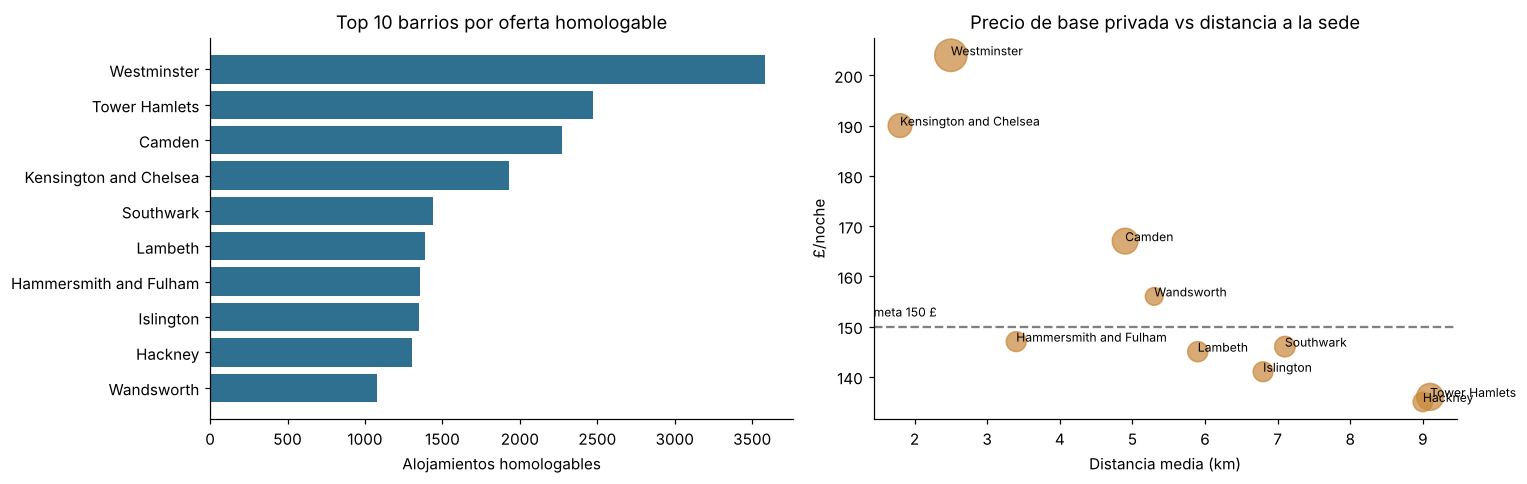

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
t = top_barrios.sort_values("homologables")
ax[0].barh(t["barrio"], t["homologables"], color="#2f6f8f")
ax[0].set(title="Top 10 barrios por oferta homologable", xlabel="Alojamientos homologables")
ax[1].scatter(top_barrios["dist_media_sede_km"], top_barrios["precio_medio_base_privada"],
              s=top_barrios["homologables"] / 8, color="#c8873a", alpha=.7)
for _, r in top_barrios.iterrows():
    ax[1].annotate(r["barrio"], (r["dist_media_sede_km"], r["precio_medio_base_privada"]), fontsize=8)
ax[1].axhline(150, ls="--", color="grey"); ax[1].text(ax[1].get_xlim()[0], 152, "meta 150 £", fontsize=8)
ax[1].set(title="Precio de base privada vs distancia a la sede", xlabel="Distancia media (km)", ylabel="£/noche")
plt.tight_layout(); plt.show()

## 6. Exportación para el informe y el dashboard

El informe (`reports/`) y el dashboard (`dashboard/`) se generan a partir de estos ficheros con `src/build_report.py` y `src/build_dashboard.py`.

In [12]:
kpis.to_csv(PROC / "kpis.csv", index=False)
con.sql("SELECT * FROM v_oferta_agregada").df().to_csv(PROC / "oferta_agregada.csv", index=False)

# Distribución de precios de la oferta homologable (tramos de 25 £), por segmento
dist = con.sql("""
    SELECT s.segmento_atlas, b.zona,
           LEAST(FLOOR(f.precio_noche / 25) * 25, 500) AS tramo_precio, COUNT(*) AS alojamientos
    FROM fact_oferta_alojamiento f
    JOIN dim_segmento s USING (id_segmento) JOIN dim_barrio b USING (id_barrio)
    WHERE f.flag_homologable = 1 GROUP BY ALL ORDER BY 1, 2, 3
""").df()
dist.to_csv(PROC / "distribucion_precios.csv", index=False)

# Muestra de alojamientos homologables para el mapa (ligera, reproducible)
mapa = con.sql("""
    SELECT f.id_alojamiento, b.barrio, b.zona, s.segmento_atlas, f.precio_noche, f.dist_sede_km,
           st.latitude, st.longitude
    FROM fact_oferta_alojamiento f
    JOIN dim_barrio b USING (id_barrio) JOIN dim_segmento s USING (id_segmento)
    JOIN stg_listings st ON st.id = f.id_alojamiento
    WHERE f.flag_homologable = 1
    USING SAMPLE 3000 ROWS (reservoir, 42)
""").df()
mapa.to_csv(PROC / "mapa_muestra.csv", index=False)
con.close()
sorted(p.name for p in PROC.iterdir())

['distribucion_precios.csv',
 'kpis.csv',
 'mapa_muestra.csv',
 'oferta_agregada.csv']

## 7. Ficha del informe y del cuadro de mando

| | **Informe de negocio** (`reports/informe_oferta_alojamiento.html`) | **Cuadro de mando** (`dashboard/index.html`) |
|---|---|---|
| **Usuario final** | Dirección de Operaciones y Logística: perfil de gestión, poco técnico | Coordinadores de logística que reservan alojamiento: uso diario |
| **Propósito** | Saber si la oferta de Londres cumple los estándares y metas, y qué decisiones tomar | Explorar la oferta apta por segmento, zona y proveedor para elegir dónde reservar |
| **Frecuencia** | **Push** mensual (por email, tras cada captura de datos) | **Pull** bajo demanda; los datos se refrescan cada mes |
| **Adopción** | Se revisa en la reunión mensual de operaciones; cada KPI en rojo tiene una acción y un responsable | Se integra en el flujo de reservas: antes de cerrar una reserva se consulta el dashboard; sesión de formación de 30 min y canal de feedback |